In [78]:
import pandas as pd
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from sklearn import preprocessing
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score, StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression, ElasticNetCV, ElasticNet, Ridge, Lasso, HuberRegressor, Lars, TheilSenRegressor, SGDRegressor, SGDClassifier, LassoLars, LassoLarsIC
from sklearn.linear_model import OrthogonalMatchingPursuit, ARDRegression, BayesianRidge, TweedieRegressor
import statsmodels.api as sm
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from statsmodels.formula.api import mnlogit
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.metrics import balanced_accuracy_score
from matplotlib.colors import ListedColormap
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.svm import LinearSVC, LinearSVR, SVC, SVR, NuSVR, NuSVC
from sklearn import svm, tree
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor

In [4]:
db_null = pd.read_csv('D:/!РАБОТА/Statistic/DB/Mall_Customers.csv')
db_null = db_null.drop(['CustomerID'], axis=1)
db_onehot = db_null.copy()
db_onehot = db_onehot.astype({'Genre': 'category'})
encoder = OneHotEncoder(drop = 'first')
encoded_data = encoder.fit_transform(db_onehot[['Genre']]).toarray()
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(['Genre']))
db_onehot = pd.concat([db_onehot, encoded_df], axis = 1)
db_onehot.drop('Genre', axis = 1, inplace = True)
db_onehot

,Age,Annual Income (k$),Spending Score (1-100),Genre_Male
0,19,15,39,1.0
1,21,15,81,1.0
2,20,16,6,0.0
3,23,16,77,0.0
4,31,17,40,0.0
...,...,...,...,...
195,35,120,79,0.0
196,45,126,28,0.0
197,32,126,74,1.0
198,32,137,18,1.0


In [93]:
# GridSearch для поиска гиперпараметров для модели GradientBoostingRegressor
x= db_onehot[['Age', 'Annual Income (k$)', 'Genre_Male']]
y = db_onehot['Spending Score (1-100)']
x = x.to_numpy()
y = y.astype('int32')

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.1,  random_state=42)

# scoring = {
#     'r2': 'r2',
#     'neg_mse': 'neg_mean_squared_error'
# }

param_grid = {
    # 'loss' : ['squared_error', 'absolute_error', 'huber', 'quantile'],
    # 'learning_rate' : [0, 0.5, 1, 5, 10],
    # 'n_estimators': [10, 25, 50, 100, 200],
    # 'criterion' : ['squared_error', 'friedman_mse'],
    # 'max_depth': [3, 5, 7, None],
    # 'min_samples_split': [2, 5, 10, 20, 50],
    # 'min_samples_leaf': [1, 2, 4],
    # 'max_features': ['sqrt', 'log2', 0.5, 1.0],
    # 'min_impurity_decrease' : [0, 1, 5, 10, 20],
    # 'ccp_alpha' : [0, 0.01, 0.001, 1, 5]
    
}

grid_search = GridSearchCV(GradientBoostingRegressor(max_depth = 3, 
    max_features = 1.0, 
    min_samples_leaf = 4,
    n_estimators = 10, 
    random_state=42,
    criterion = 'squared_error',
    min_samples_split = 20,
    loss = 'squared_error',
    ccp_alpha = 5,
    min_impurity_decrease = 10,
    learning_rate = 1,
    alpha = 0.1
), param_grid, cv=3, scoring= 'r2', n_jobs = -1, verbose = 2)

grid_search.fit(x_train, y_train)
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший MSE:", -grid_search.best_score_)
best_model = grid_search.best_estimator_
print(best_model)

Fitting 3 folds for each of 1 candidates, totalling 3 fits
Лучшие параметры: {}
Лучший MSE: -0.25973432569688315
GradientBoostingRegressor(alpha=0.1, ccp_alpha=5, criterion='squared_error',
                          learning_rate=1, max_features=1.0,
                          min_impurity_decrease=10, min_samples_leaf=4,
                          min_samples_split=20, n_estimators=10,
                          random_state=42)


In [71]:
# Теперь построим модель на основе GradientBoostingRegressor
x= db_onehot[['Age', 'Annual Income (k$)', 'Genre_Male']]
y = db_onehot['Spending Score (1-100)']
x = x.to_numpy()
y = y.astype('int32')

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.1,  random_state=42)

model_GradientBoostingRegressor = GradientBoostingRegressor(
    alpha=0.1, 
    ccp_alpha=5, 
    criterion='squared_error',
    learning_rate=1, 
    max_features=1.0,
    min_impurity_decrease=10, 
    min_samples_leaf=4,
    min_samples_split=20, 
    n_estimators=50,
    random_state=42, 
    max_depth = 3
)

model_GradientBoostingRegressor.fit(x_train, y_train)
y_pred = model_GradientBoostingRegressor.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Среднеквадратическая ошибка: {mse}')
print(f'R^2 Score: {r2}')
print('----------------------------------------------------')
print (f'Кол-во параметров: { model_GradientBoostingRegressor.n_features_in_}')
print(model_GradientBoostingRegressor.get_params())
print(model_GradientBoostingRegressor.get_metadata_routing())
print(model_GradientBoostingRegressor.score(x_test, y_test))
mae = mean_absolute_error(y_test, y_pred)
print(f"MAE: {mae:.3f}")
print ('feature_importances_ :', model_GradientBoostingRegressor.feature_importances_)
# print ('OOB R²:', model_GradientBoostingRegressor.oob_score_)
# print ('oob_prediction_ :', model_RandomForestRegressor.oob_prediction_)

Среднеквадратическая ошибка: 345.55788060565067
R^2 Score: 0.4043645943193128
----------------------------------------------------
Кол-во параметров: 3
{'alpha': 0.1, 'ccp_alpha': 5, 'criterion': 'squared_error', 'init': None, 'learning_rate': 1, 'loss': 'squared_error', 'max_depth': 3, 'max_features': 1.0, 'max_leaf_nodes': None, 'min_impurity_decrease': 10, 'min_samples_leaf': 4, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 50, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
{'fit': {'sample_weight': None, 'monitor': None}, 'score': {'sample_weight': None}}
0.4043645943193128
MAE: 12.721
feature_importances_ : [0.66508356 0.33491644 0.        ]


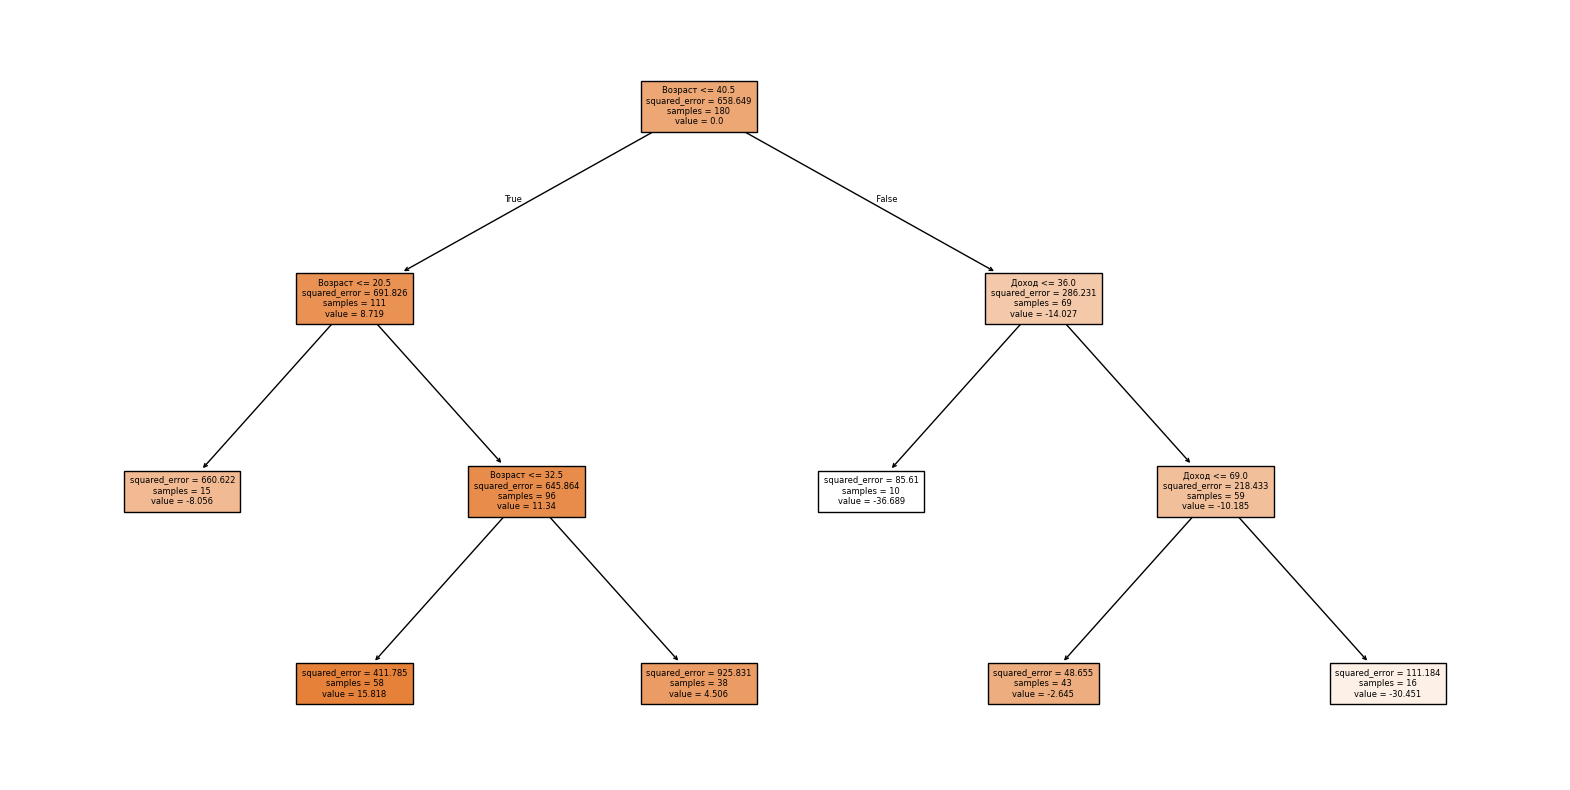

In [84]:
# Визуализация дерева
plt.figure(figsize=(20, 10))
plot_tree(
    model_GradientBoostingRegressor.estimators_[0][0],
    feature_names=['Возраст', 'Доход', 'Пол'],
    filled=True,
    rounded=False,
    fontsize=6
)
plt.show()

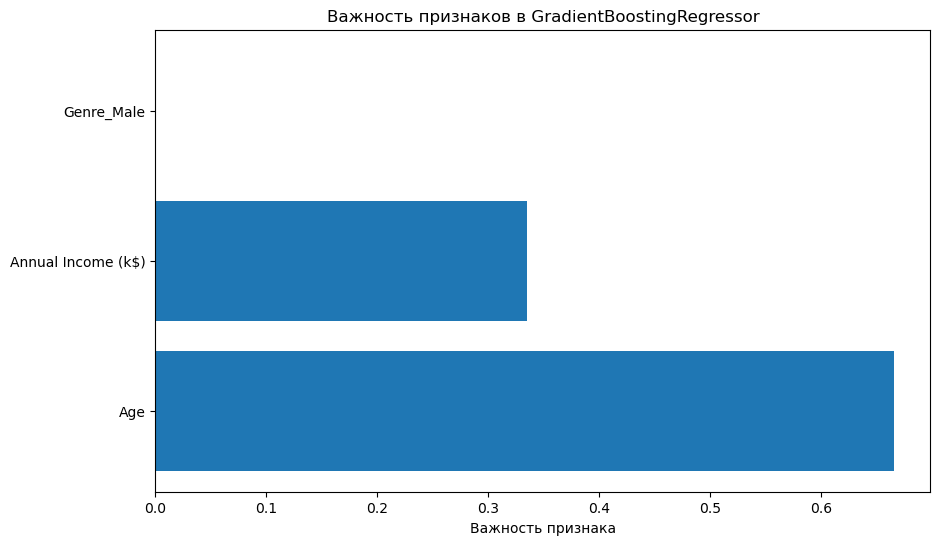

In [85]:
plt.figure(figsize=(10, 6))
plt.barh(range(len(model_GradientBoostingRegressor.feature_importances_)), model_GradientBoostingRegressor.feature_importances_)
plt.yticks(range(3), ['Age', 'Annual Income (k$)', 'Genre_Male'])
plt.xlabel("Важность признака")
plt.title("Важность признаков в GradientBoostingRegressor")
plt.show()

In [86]:
# Вычисление важности признаков
perm_importance = permutation_importance(
    estimator=model_GradientBoostingRegressor,
    X=x_test,
    y=y_test,
    n_repeats=10,           # число перестановок для каждого признака
    random_state=42,
    scoring='r2'  # метрика качества (можно использовать 'r2', 'neg_mean_absolute_error' и др.)
)

# Средние значения важности
importances_mean = perm_importance.importances_mean

# Стандартные отклонения
importances_std = perm_importance.importances_std

# Индексы признаков, отсортированные по важности
sorted_idx = importances_mean.argsort()[::-1]  # убывание

# Вывод результатов
feature_names = ['Age', 'Annual Income (k$)', 'Genre_Male']  # замените на свои

print("Важность признаков (по убыванию):")
for idx in sorted_idx:
    print(f"{feature_names[idx]}: {importances_mean[idx]:.4f} ± {importances_std[idx]:.4f}")

Важность признаков (по убыванию):
Age: 1.0074 ± 0.3741
Annual Income (k$): 0.3744 ± 0.0562
Genre_Male: 0.0000 ± 0.0000


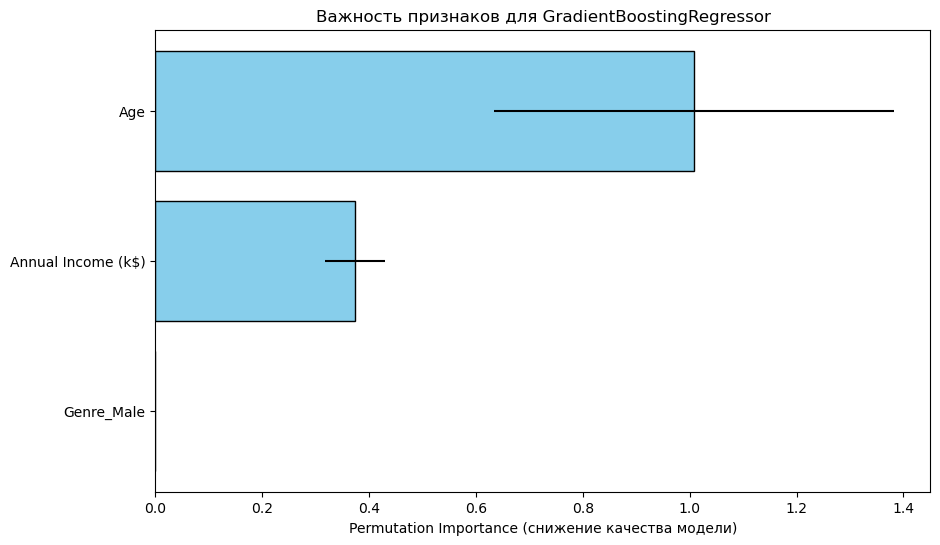

In [87]:
# Визуализация
plt.figure(figsize=(10, 6))
plt.barh(
    [feature_names[i] for i in sorted_idx],
    importances_mean[sorted_idx],
    xerr=importances_std[sorted_idx],
    color='skyblue',
    edgecolor='black'
)
plt.xlabel('Permutation Importance (снижение качества модели)')
plt.title('Важность признаков для GradientBoostingRegressor')
plt.gca().invert_yaxis()  # сортировка от самого важного
plt.show()

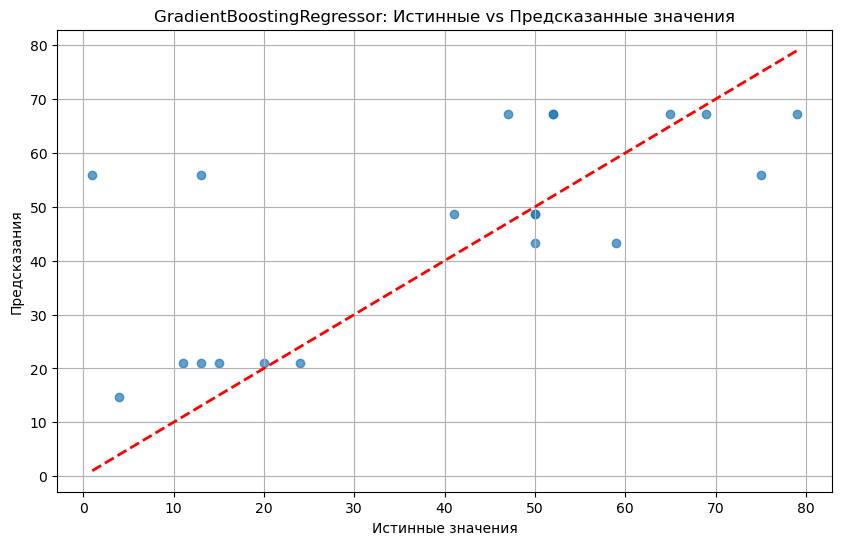

In [88]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Истинные значения")
plt.ylabel("Предсказания")
plt.title("GradientBoostingRegressor: Истинные vs Предсказанные значения")
plt.grid()
plt.show()

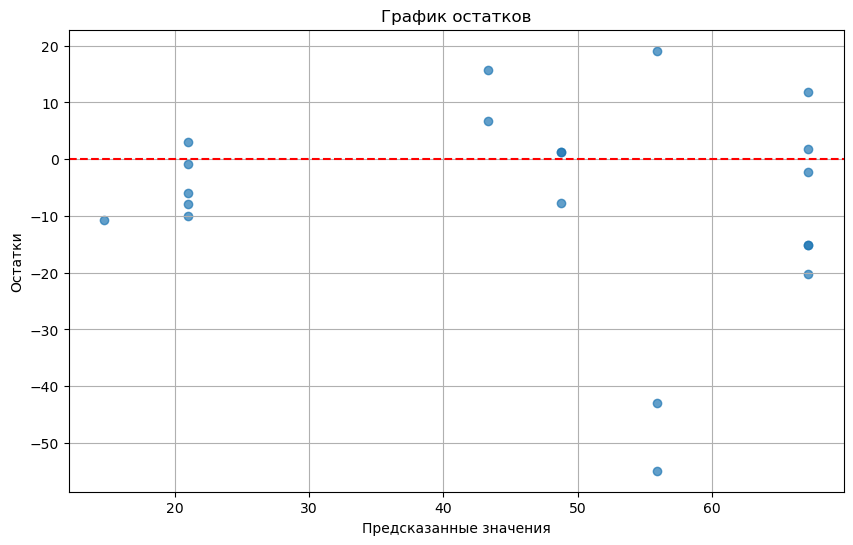

In [89]:
# Визуализация остатков
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Предсказанные значения")
plt.ylabel("Остатки")
plt.title("График остатков")
plt.grid()
plt.show()

In [90]:
# Проверка на переобучение
train_r2 = model_GradientBoostingRegressor.score(x_train, y_train)
test_r2 = model_GradientBoostingRegressor.score(x_test, y_test)
print(f"R² (train): {train_r2:.3f}")
print(f"R² (test): {test_r2:.3f}")
print(f"Разница: {train_r2 - test_r2:.3f}")

R² (train): 0.378
R² (test): 0.404
Разница: -0.026


In [91]:
new_data = [[31, 17, 0]]
y__pred_2 = model_GradientBoostingRegressor.predict(new_data)
y__pred_2

array([67.20689655])

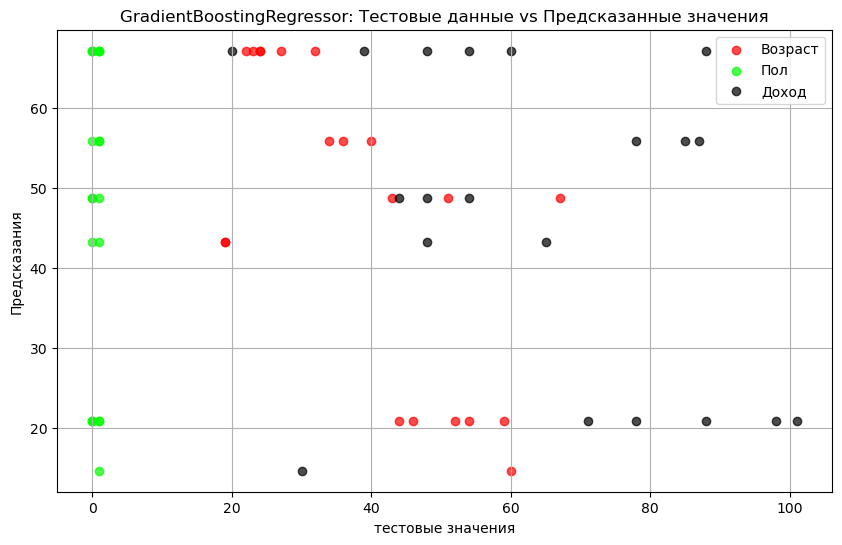

In [92]:
plt.figure(figsize=(10, 6))
plt.scatter(x_test[:, 0], y_pred, alpha=0.7, color = 'red', label = 'Возраст') # Возраст
plt.scatter(x_test[:, 2], y_pred, alpha=0.7, color = 'lime', label = 'Пол') # Пол
plt.scatter(x_test[:, 1], y_pred, alpha=0.7, color = 'black', label = 'Доход') # Доход
plt.xlabel("тестовые значения")
plt.legend()
plt.ylabel("Предсказания")
plt.title("GradientBoostingRegressor: Тестовые данные vs Предсказанные значения")
plt.grid()
plt.show()